# 03 · Illustrations for the documentation

**Why.** The pages in `docs/` explain the benchmark with real examples from the world, and GitHub shows them as static
Markdown. This notebook draws those examples with the same oracle the benchmark scores with, so every number in a
figure is computed. It writes PNG files to `docs/figures/`.

**What.** All three figures use one task, *Asteroid* → *Viking*, because it is small enough to draw whole and
people played it 1,770 times:

1. the two routes that are optimal in the two cost models;
2. the graph of every shortest path, with one human game drawn on top;
3. the cost to go and the bits to go after each step of that game.

**Runtime.** About 5 s. It needs the world from notebook 01 and the task files from notebook 02.

In [1]:
import json
import textwrap
from collections import deque

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

from wikigame.world import World
from wikigame.metrics import Graphs, Oracle, score_pages, score_actions
from wikigame.env import WikiGameEnv
from wikigame import style
from wikigame.style import INK, INK2, MUTED, GRID, AXIS, MID, BLUE, BLUE_WASH, RED, RED_WASH

style.use()
world = World.load("wikispeedia")
g = Graphs.build(world)
START, TARGET = world.index["Asteroid"], world.index["Viking"]
oracle = Oracle(world, g, TARGET)
task = json.load(open(world.dir / "tasks" / f"{START}-{TARGET}.json"))
name = world.name_of

## What the agent sees

The first observation of the task, exactly as a language model receives it. The chunk is cut here to its first
lines; the real one runs to about 2,000 characters.

In [2]:
env = WikiGameEnv(world, oracle, START, max_steps=30)
obs = env.observe().split("\n")
cut = obs.index("-----", 4)
print("\n".join(obs[:cut - 1] + [obs[cut - 1][:600] + " …"] + obs[cut:]))

Goal: reach the Wikipedia page "Viking" by following links, in as few actions as possible.
You are on "Asteroid", part 1 of 13 (scroll down for more).
Actions used: 0 of 30.
-----
253 Mathilde, a C-type asteroid.

Asteroids, also called minor planets or planetoids, are a class of astronomical object. The term asteroid is generally used to indicate a diverse group of small celestial bodies that drift in the [solar system](Solar System) in orbit around the [Sun](Sun). Asteroid (Greek for "star-like") is the word used most in the English literature for minor planets, which has been the term preferred by the International Astronomical Union; some other languages prefer planetoid (Greek: "planet-like"), because it more accurately describes what they are. In late August 2006, the IAU introduced the term " small solar system bodies" (SSSBs), which includes most objects thusfar classified as minor planets, as well as [comets](Comet). At the same time they introduced the term dwarf planet for t

## Two cost models, two routes

In the *clicks* model only clicks count, so the best route is a shortest path in the link graph. In the *actions*
model the agent sees one chunk at a time and every scroll costs a step too. The best route then prefers links near
the top of each page. We find the best route of each kind by breadth-first search on the graph of (page, chunk)
states. For the clicks model the search may only click links that bring it one click closer, and among those routes
it takes the one with the fewest scrolls.

In [3]:
def fewest_actions(o, start, only_shortest_clicks):
    # Breadth-first search over (page, chunk) states; returns the list of states visited, start included.
    keep = np.ones(len(g.state_src), dtype=bool)
    if only_shortest_clicks:
        p_src, p_dst = g.state_page[g.state_src], g.state_page[g.state_dst]
        keep = (g.state_kind != 0) | (o.d[p_dst] == o.d[p_src] - 1)
    adj = {}
    for a, b in zip(g.state_src[keep], g.state_dst[keep]):
        adj.setdefault(int(a), []).append(int(b))
    x0 = o.state(start)
    prev, queue = {x0: None}, deque([x0])
    while queue:
        x = queue.popleft()
        if g.state_page[x] == o.target:
            break
        for y in adj.get(x, []):
            if y not in prev:
                prev[y] = x
                queue.append(y)
    path = []
    while x is not None:
        path.append(x)
        x = prev[x]
    return [(int(g.state_page[x]), int(x - g.offsets[g.state_page[x]])) for x in path[::-1]]

def describe(states):
    clicks = sum(1 for a, b in zip(states, states[1:]) if a[0] != b[0])
    return clicks, len(states) - 1 - clicks

routes = {}
for label, only in [("Fewest clicks", True), ("Fewest actions", False)]:
    states = fewest_actions(oracle, START, only)
    clicks, scrolls = describe(states)
    routes[label] = states
    print(f"{label}: {clicks} clicks + {scrolls} scrolls = {clicks + scrolls} actions:",
          " → ".join(dict.fromkeys(name(p) for p, _ in states)))

smog, toy = world.index["Smog"], world.index["Toy_Story"]
o2 = Oracle(world, g, toy)
for label, only in [("Fewest clicks", True), ("Fewest actions", False)]:
    clicks, scrolls = describe(fewest_actions(o2, smog, only))
    print(f"Smog → Toy Story, {label.lower()}: {clicks} clicks + {scrolls} scrolls = {clicks + scrolls} actions")

Fewest clicks: 3 clicks + 3 scrolls = 6 actions: Asteroid → Comet → English language → Viking
Fewest actions: 5 clicks + 0 scrolls = 5 actions: Asteroid → Comet → English language → England → 10th century → Viking
Smog → Toy Story, fewest clicks: 5 clicks + 25 scrolls = 30 actions
Smog → Toy Story, fewest actions: 7 clicks + 18 scrolls = 25 actions


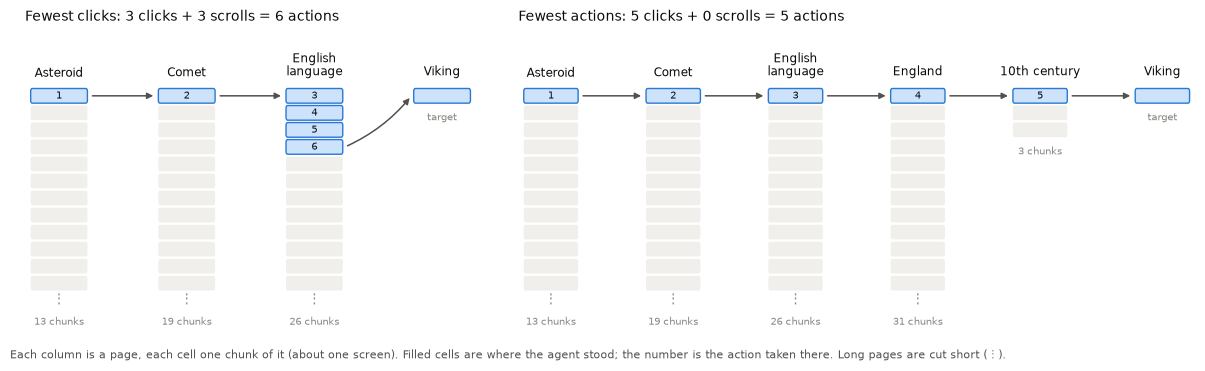

In [4]:
CELL_H, CELL_W, COL_GAP, MAX_CELLS = 0.2, 1.0, 1.25, 12

def draw_route(ax, states, title):
    # one column per page; one cell per chunk; visited cells carry the number of the action taken there
    columns = []
    for i, (p, c) in enumerate(states):
        if not columns or columns[-1]["page"] != p:
            columns.append({"page": p, "visits": []})
        columns[-1]["visits"].append((i, c))
    centre = {}
    for j, col in enumerate(columns):
        x = j * (CELL_W + COL_GAP)
        p = col["page"]
        k = 1 if p == TARGET else world.n_chunks(p)
        seen = {c: i for i, c in col["visits"]}
        shown = min(k, MAX_CELLS)
        for c in range(shown):
            y = -c * CELL_H
            on = c in seen
            ax.add_patch(FancyBboxPatch((x, y - CELL_H * 0.86), CELL_W, CELL_H * 0.86, boxstyle="round,pad=0,rounding_size=0.03",
                                        facecolor=BLUE_WASH if on else MID, edgecolor=BLUE if on else "none", linewidth=1))
            if on and p != TARGET:
                ax.text(x + CELL_W / 2, y - CELL_H * 0.43, str(seen[c] + 1), ha="center", va="center", fontsize=7.5, color=INK)
            centre[(p, c)] = (x, y - CELL_H * 0.43)
        label = "\n".join(textwrap.wrap(name(p), 14))
        sub = "target" if p == TARGET else f"{k} chunks"
        ax.text(x + CELL_W / 2, 0.12, label, ha="center", va="bottom", fontsize=8.5, color=INK, linespacing=1.1)
        if k > shown:
            ax.text(x + CELL_W / 2, -shown * CELL_H, "⋮", ha="center", va="top", fontsize=9, color=MUTED)
            shown += 1
        ax.text(x + CELL_W / 2, -shown * CELL_H - 0.08, sub, ha="center", va="top", fontsize=7.5, color=MUTED)
    for (p, c), (q, d) in zip(states, states[1:]):
        if p != q:
            x0, y0 = centre[(p, c)]
            x1, y1 = centre[(q, d)]
            ax.add_patch(FancyArrowPatch((x0 + CELL_W + 0.04, y0), (x1 - 0.04, y1), arrowstyle="-|>", mutation_scale=9,
                                         color=INK2, linewidth=1.1, connectionstyle="arc3,rad=0.12" if c else "arc3,rad=0"))
    clicks, scrolls = describe(states)
    ax.set_title(f"{title}: {clicks} clicks + {scrolls} scrolls = {clicks + scrolls} actions", loc="left", fontsize=10, color=INK, pad=12)
    ax.set_axis_off()
    return len(columns)

n_cols = [len(dict.fromkeys(p for p, _ in st)) for st in routes.values()]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": n_cols})
for ax, (label, states), n in zip(axes, routes.items(), n_cols):
    draw_route(ax, states, label)
    ax.set_xlim(-0.1, n * (CELL_W + COL_GAP) - COL_GAP + 0.1)
    ax.set_ylim(-(MAX_CELLS + 1) * CELL_H - 0.35, 0.6)
fig.text(0.0, -0.01, "Each column is a page, each cell one chunk of it (about one screen). Filled cells are where the agent stood; "
         "the number is the action taken there. Long pages are cut short (⋮).", fontsize=8, color=INK2)
plt.tight_layout(w_pad=3)
style.save(fig, "two_routes")

## The graph of shortest paths, with one human game

The oracle knows every page that lies on some shortest path from *Asteroid* to *Viking*. We draw them by their
distance to the target, so the start is on the left and the target on the right. A page's size is the number of
shortest paths through it. On top we draw the game of one person from the Wikispeedia logs (person 2 in the viewer).
Pages that person visited off every shortest path sit in a band below. A click is red when it has regret, which
means it did not bring the player one click closer.

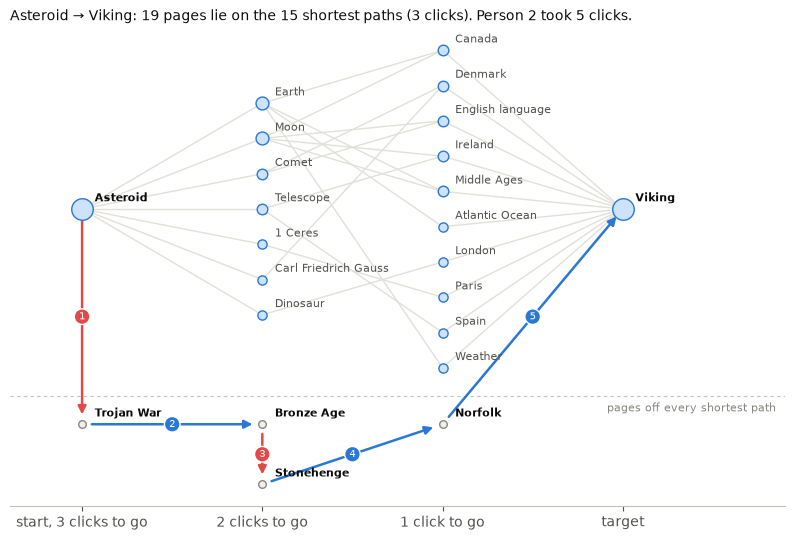

In [5]:
HUMAN = 1   # person 2 in the viewer
pages = task["humans"][HUMAN]["pages"]
steps, summary = score_pages(oracle, pages)
layers, edges, through = oracle.dag(START)
on_dag = {int(v) for L in layers for v in L}
D = int(oracle.d[START])

pos = {}
for k, L in enumerate(layers):
    L = sorted(L.tolist(), key=lambda v: (-through[v], name(v)))
    for i, v in enumerate(L):
        pos[v] = (k, (len(L) - 1) / 2 - i)
band = min(y for _, y in pos.values()) - 1.6
off = [p for p in dict.fromkeys(pages) if p not in on_dag]
for p in off:
    x = D - int(oracle.d[p])
    pos[p] = (x, band - 1.7 * sum(1 for q in off if q in pos and pos[q][0] == x and q != p))

fig, ax = plt.subplots(figsize=(10, 6.2))
for a, b in edges:
    (x0, y0), (x1, y1) = pos[a], pos[b]
    ax.plot([x0, x1], [y0, y1], color=GRID, linewidth=1, zorder=1)
for s in steps:
    (x0, y0), (x1, y1) = pos[s["from"]], pos[s["to"]]
    colour = BLUE if s["regret"] == 0 else RED
    ax.add_patch(FancyArrowPatch((x0, y0), (x1, y1), arrowstyle="-|>", mutation_scale=12, color=colour, linewidth=1.8,
                                 shrinkA=7, shrinkB=7, zorder=3))
    mx, my = (x0 + x1) / 2, (y0 + y1) / 2
    ax.text(mx, my, str(s["step"]), ha="center", va="center", fontsize=7.5, color="white", zorder=5,
            bbox=dict(boxstyle="circle,pad=0.25", facecolor=colour, edgecolor="white", linewidth=1))
for v, (x, y) in pos.items():
    dag = v in on_dag
    size = 30 + 14 * through[v] if dag else 30
    ax.scatter([x], [y], s=size, facecolor=BLUE_WASH if dag else MID, edgecolor=BLUE if dag else MUTED, linewidth=1, zorder=4)
    bold = v in (START, TARGET) or v in pages
    ax.text(x + 0.07, y + 0.22, name(v), fontsize=8, color=INK if bold else INK2, weight="bold" if bold else "normal", zorder=6)
ax.axhline(band + 0.8, color=AXIS, linewidth=0.8, linestyle=(0, (3, 3)))
ax.text(D + 0.85, band + 0.62, "pages off every shortest path", fontsize=8, color=MUTED, va="top", ha="right")
ax.set_xticks(range(D + 1), [f"{D - k} click{'s' if D - k > 1 else ''} to go" if k not in (0, D) else ("start, 3 clicks to go" if k == 0 else "target") for k in range(D + 1)])
ax.set_yticks([])
ax.grid(False)
ax.spines["left"].set_visible(False)
ax.set_xlim(-0.4, D + 0.9)
ax.set_title(f"Asteroid → Viking: {len(on_dag)} pages lie on the {int(oracle.n_paths_to[START])} shortest paths (3 clicks). "
             f"Person 2 took {summary['steps']} clicks.", loc="left")
style.save(fig, "shortest_path_graph")

## Cost and bits after each step of that game

The same game, step by step. *Cost to go* is the fewest clicks still needed. *Bits to go* is −log₂ of the chance that
a player who clicks at random from here follows a shortest path to the target. For comparison, the dashed line is
one shortest path, the one whose next page is easiest at every step.

,step,from,to,cost_before,cost_after,regret,n_actions,n_optimal,chance_bits,phi_before,phi_after,info_gain
0,1,Asteroid,Trojan War,3,3,1,19,7,1.44,11.96,10.76,1.19
1,2,Trojan War,Bronze Age,3,2,0,41,25,0.71,10.76,8.63,2.14
2,3,Bronze Age,Stonehenge,2,2,1,35,5,2.81,8.63,7.77,0.85
3,4,Stonehenge,Norfolk,2,1,0,27,5,2.43,7.77,4.95,2.82
4,5,Norfolk,Viking,1,0,0,31,1,4.95,4.95,-0.00,4.95


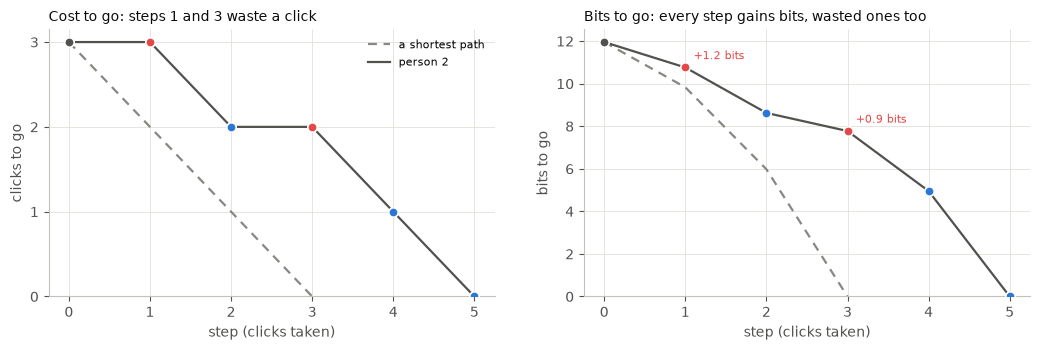

In [6]:
best = [START]
while best[-1] != TARGET:
    outs = g.page_dst[g.page_src == best[-1]]
    good = outs[oracle.d[outs] == oracle.d[best[-1]] - 1]
    best.append(int(good[np.argmax(oracle.P_page[good])]))

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6))
for ax, key, label in [(axes[0], "cost", "clicks to go"), (axes[1], "phi", "bits to go")]:
    def series(seq):
        return [oracle.d[p] if key == "cost" else oracle.phi_page[p] for p in seq]
    ax.plot(range(len(best)), series(best), color=MUTED, linestyle=(0, (4, 3)), linewidth=1.6, label="a shortest path")
    ys = series(pages)
    ax.plot(range(len(pages)), ys, color=INK2, linewidth=1.6, label="person 2", zorder=2)
    for s in steps:
        bad = s["regret"] != 0
        ax.scatter([s["step"]], [ys[s["step"]]], s=46, color=RED if bad else BLUE, edgecolor="white", linewidth=1.2, zorder=3)
    ax.scatter([0], [ys[0]], s=46, color=INK2, edgecolor="white", linewidth=1.2, zorder=3)
    ax.set(xlabel="step (clicks taken)", ylabel=label, xticks=range(len(pages)))
    ax.set_ylim(bottom=0)
axes[0].set_yticks(range(int(oracle.d[START]) + 1))
axes[0].set_title("Cost to go: steps 1 and 3 waste a click", loc="left")
axes[1].set_title("Bits to go: every step gains bits, wasted ones too", loc="left")
axes[0].legend(loc="upper right", fontsize=8)
for s in steps:
    if s["regret"] != 0:
        axes[1].annotate(f"+{s['info_gain']:.1f} bits", (s["step"], s["phi_after"]), xytext=(6, 6), textcoords="offset points",
                         fontsize=8, color=RED)
plt.tight_layout(w_pad=3)
style.save(fig, "steps_of_a_game")

import pandas as pd
table = pd.DataFrame(steps)
table["from"] = table["from"].map(name)
table["to"] = table["to"].map(name)
table[["step", "from", "to", "cost_before", "cost_after", "regret", "n_actions", "n_optimal", "chance_bits", "phi_before", "phi_after", "info_gain"]].round(2)

The red steps waste a click and still gain bits. Each one lands on a page with many links that lead closer
(a *hub*). From there, a random clicker is more likely to follow a shortest path than from the page the person left,
even though the target is just as far away. So regret, not bits, is the signal for a wasted step; bits measure how
much easier the remaining choice became.